# Test II - Agentic workflow around DeepLenseSim

**Task:** natural-language prompt -> Pydantic AI agent -> DeepLenseSim -> images + structured metadata, with a human-in-the-loop step and at least two model configurations.

**What is in this repo**

| file | job |
|---|---|
| `deeplense_agent/schemas.py` | Pydantic models: `SimulationParams` (validated input), `SimulationResult` (output built by code) |
| `deeplense_agent/simulator.py` | thin wrapper around DeepLenseSim for **Model_I** and **Model_II** |
| `deeplense_agent/ui.py` | how the agent talks to the human (`ConsoleUI`, `ScriptedUI`, `PersonaUI`) |
| `deeplense_agent/agent.py` | the Pydantic AI agent, its three tools, and the conversation loop `simulate()` |
| `deeplense_agent/llm_configs.py` | local LLM backends through Ollama |
| `tests/test_agent.py` | 23 tests that need no LLM (a scripted `FunctionModel` plays the model) |

Run everything with the Python 3.11 environment in `.venv-sim` (DeepLenseSim needs old library versions, see section 0).

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
from pydantic import ValidationError

from deeplense_agent import PersonaUI, SimulationParams, simulate
from deeplense_agent import simulator
from deeplense_agent.llm_configs import QWEN25

OUT = ROOT / "outputs" / "notebook_runs"
RUN_LIVE_LLM = True   # the live cells call a local 7B model on CPU: about 1-3 minutes per case

## 0. Understand DeepLenseSim first

DeepLenseSim builds a strong-lensing image from a main halo plus an optional substructure, using lenstronomy and pyHalo:

- `DeepLens(...)`, then `make_single_halo(mass)`
- the substructure: `make_no_sub()`, `make_old_cdm()` (CDM subhalos) or `make_vortex(mass)` (axion / superfluid vortex, needs an axion mass)
- the source and the simulation, which differ per model: **Model_I** uses `make_source_light()` + `simple_sim()` (150x150 pixels); **Model_II** uses `set_instrument('Euclid')` + `make_source_light_mag()` + `simple_sim_2()` (64x64 pixels, Euclid VIS)

Two practical findings while setting this up:

1. The library only works with an old, specific set of versions (lenstronomy 1.9.2, pyHalo at its June 2022 commit, numba 0.58, scipy < 1.14, astropy 5.3, numpy < 1.27). Newer pyHalo needs a newer lenstronomy that DeepLenseSim does not support.
2. The **resolution is fixed by the model config** (150 px or 64 px), so a user asking for "128x128" cannot be served directly. The agent has to say that, not silently ignore it.

Below: one image per lens type from Model_I, straight from the wrapper.

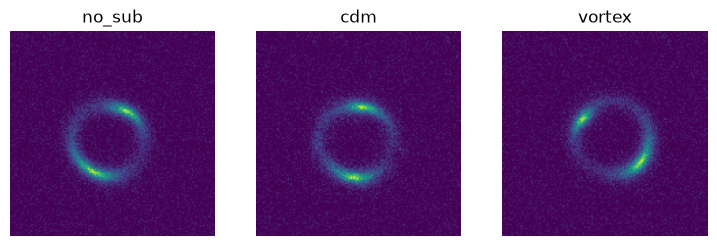

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, sub in zip(axes, ["no_sub", "cdm", "vortex"]):
    extra = {"axion_mass": 1e-23} if sub == "vortex" else {}
    res = simulator.run_simulation(SimulationParams(model_name="Model_I", substructure=sub, num_images=1, seed=3, **extra), OUT)
    ax.imshow(np.load(res.files[0])); ax.set_title(sub); ax.axis("off")
plt.show()

## 1. Pydantic models for the simulation parameters

`SimulationParams` is the only door into the simulator. It checks ranges and combinations, so a bad request fails with a readable message *before* any compute. Examples of what it rejects:

In [3]:
good = SimulationParams(model_name="Model_II", substructure="vortex", num_images=3, axion_mass=1e-23, seed=1)
print("accepted:", good.model_dump())

bad_requests = {
    "too many images": dict(model_name="Model_I", substructure="cdm", num_images=1000),
    "lens behind the source": dict(model_name="Model_I", substructure="cdm", num_images=1, z_halo=2.0, z_gal=1.0),
    "vortex without axion mass": dict(model_name="Model_I", substructure="vortex", num_images=1),
    "axion mass on a CDM lens": dict(model_name="Model_I", substructure="cdm", num_images=1, axion_mass=1e-23),
    "unknown model": dict(model_name="Model_IX", substructure="cdm", num_images=1),
}
for label, kwargs in bad_requests.items():
    try:
        SimulationParams(**kwargs)
    except ValidationError as e:
        err = e.errors()[0]
        print(f"rejected - {label}: {err['msg']}")

accepted: {'model_name': 'Model_II', 'substructure': 'vortex', 'num_images': 3, 'halo_mass': 1000000000000.0, 'axion_mass': 1e-23, 'z_halo': 0.5, 'z_gal': 1.0, 'seed': 1}
rejected - too many images: Input should be less than or equal to 25
rejected - lens behind the source: Value error, z_halo (2.0) must be smaller than z_gal (1.0): the lens has to be in front of the source.
rejected - vortex without axion mass: Value error, axion_mass is required when substructure is 'vortex'.
rejected - axion mass on a CDM lens: Value error, axion_mass only applies to substructure='vortex'.
rejected - unknown model: Input should be 'Model_I' or 'Model_II'


## 2. Tool functions

`simulator.run_simulation(params, output_root)` is a plain function: it validates nothing itself (the model did that), runs the right DeepLenseSim call order for the chosen model, saves each image as `.npy`, writes a preview grid and a `metadata.json`, and returns a `SimulationResult`. Because the result is built by code, the agent cannot invent file paths or image statistics.

The same request on both model configurations (same seed, CDM subhalos):

Model_I: shape=(150, 150), pixel scale=0.050 arcsec, instrument=generic (Gaussian PSF), 5.83s


Model_II: shape=(64, 64), pixel scale=0.101 arcsec, instrument=Euclid VIS, 5.79s


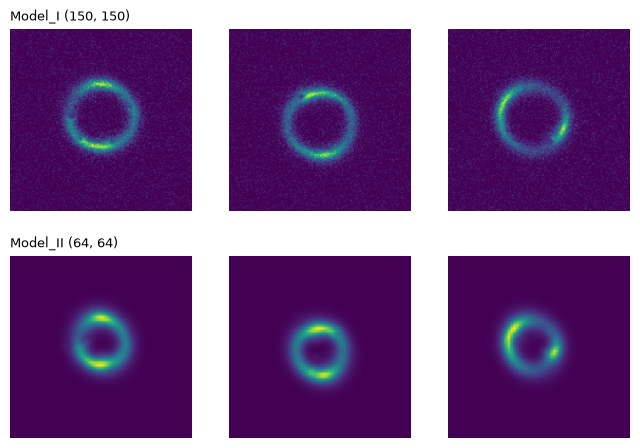

In [4]:
rows = {}
for name in ["Model_I", "Model_II"]:
    res = simulator.run_simulation(SimulationParams(model_name=name, substructure="cdm", num_images=3, seed=11), OUT)
    rows[name] = res
    print(f"{name}: shape={res.image_shape}, pixel scale={res.pixel_scale_arcsec:.3f} arcsec, instrument={res.instrument}, {res.elapsed_seconds}s")
fig, axes = plt.subplots(2, 3, figsize=(8, 5.4))
for r, (name, res) in enumerate(rows.items()):
    for c in range(3):
        axes[r, c].imshow(np.load(res.files[c])); axes[r, c].axis("off")
    axes[r, 0].set_title(f"{name} {res.image_shape}", loc="left", fontsize=9)
plt.show()

## 3. The agent (Pydantic AI)

**Backend.** A local LLM through Ollama, so no API key and no cost. The first model I tried, `llama3`, is rejected by Ollama with *"does not support tools"*, which an agent needs. `qwen2.5:7b` lists the `tools` capability and is what the live cells below use. It runs on CPU here, so each model call takes roughly a minute.

**Design.**
- Tools: `get_options()` (what is allowed), `ask_user(question)` (human-in-the-loop), `run_simulation(params: SimulationParams)` (shows the plan, waits for approval, then simulates).
- `run_simulation` takes the Pydantic model as its argument, so Pydantic AI validates the LLM's arguments and sends validation errors back to the model for a retry. The invalid call never reaches the user or the simulator.
- The agent's final text is only a summary. Paths and numbers come from `SimulationResult`.
- The instructions forbid guessing missing values and fix the optional ones at their defaults.

In [5]:
from deeplense_agent.agent import INSTRUCTIONS, build_agent
print(INSTRUCTIONS)
agent = build_agent("test")
print("tools:", sorted(getattr(getattr(agent, "_function_toolset", None), "tools", {}) or ["get_options", "ask_user", "run_simulation"]))

You help a physicist generate simulated strong gravitational lensing images with DeepLenseSim.

Rules:
1. Call get_options first if you are unsure what is allowed.
2. A simulation needs: model_name, substructure and num_images. If the user did not say one of
   them clearly, do NOT guess. Call ask_user with ONE short question about what is missing.
3. Image size cannot be chosen freely: it comes from the model (Model_I is 150x150 pixels,
   Model_II is Euclid 64x64 pixels). If the user asks for a resolution, ask which model they want
   or explain this.
4. substructure='vortex' needs an axion_mass between 1e-24 and
   1e-22 eV. If it is missing, ask for it (1e-23 is a reasonable suggestion).
5. At most 25 images per request.
6. Only call run_simulation when every value is known. It shows the plan to the user, who may
   decline with a change request. If declined, apply the change and call it again.
7. Leave halo_mass, z_halo, z_gal, seed and axion_mass at their defaults (or unset) unle

## 4. Human-in-the-loop

Two places where a human is involved:

1. **Clarifying questions.** If the model, substructure or number of images is missing or unclear, the agent asks (`ask_user`). Small models often write the question as plain text instead of calling the tool, so `simulate()` also treats a text reply containing a `?` as a question for the human and feeds the answer back.
2. **Approval gate.** `run_simulation` prints the exact plan and waits. The human can approve, or decline with a change request, which goes back to the model.

All interaction goes through a `UserInterface`: `ConsoleUI` uses `input()` (works in a notebook), `ScriptedUI` and `PersonaUI` give reproducible answers for tests and demos. A `PersonaUI` is a simulated user who answers by keyword.

To try it yourself: `await simulate("your prompt", model=QWEN25.build(), ui=ConsoleUI(), output_root=OUT)`.

## 5. Two model configurations

Model_I and Model_II are both supported end to end: same agent, same tools, different DeepLenseSim call sequence, image size and pixel scale (section 2 shows them side by side, and the live cases below pick them from the prompt or from the user's answer). `tests/test_agent.py` also checks every combination of {Model_I, Model_II} x {no_sub, cdm, vortex}.

In [6]:
import subprocess
r = subprocess.run([sys.executable, "-m", "pytest", "tests", "-q", "-p", "no:cacheprovider", "-W", "ignore", "--color=no"],
                   cwd=ROOT, capture_output=True, text=True, env={**__import__("os").environ, "PYDANTIC_AI_NO_BANNER": "1"})
print(r.stdout.strip().splitlines()[-1])

23 passed in 52.76s


## 6. Demonstrations (live, local `qwen2.5:7b`)

Four prompts: a complete one, a vague one, one with an invalid value, and an off-topic one. The "user" is a `PersonaUI`, so the run is repeatable, but the **LLM is not deterministic**: a rerun can word its questions differently or fail differently (see section 7).

In [7]:
async def show(prompt, profile, label):
    ui = PersonaUI(profile=profile)
    print(f"=== {label}: {prompt!r}")
    t = time.time()
    try:
        out = simulate(prompt, model=QWEN25.build(), ui=ui, output_root=OUT)
        out = await out
    except Exception as e:
        print("  FAILED:", type(e).__name__, str(e)[:200]); return None
    for who, text in out.transcript:
        print(f"  [{who}] {text[:230]}".replace("\n", " | "))
    for r in out.results:
        p = r.params
        print(f"  -> {p.model_name} / {p.substructure} / {p.num_images} images / shape {r.image_shape} / axion={p.axion_mass}")
        display(Image(filename=r.grid_png, width=520))
    print("  reply:", out.reply.message[:300].replace("\n", " | "))
    print(f"  ({time.time() - t:.0f}s)\n")
    return out

=== complete request: 'Generate 2 Model_II images with no substructure, seed 5'


  [agent] Confirm:   model       : Model_II |   substructure: no_sub |   images      : 2 |   halo mass   : 1e+12 solar masses |   redshifts   : lens z=0.5, source z=1.0 |   seed        : 5
  [user] yes
  -> Model_II / no_sub / 2 images / shape (64, 64) / axion=None


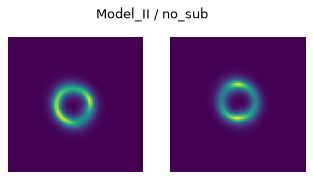

  reply: Your simulation is complete. The images were generated using Model_II with no substructure and a seed of 5. Each image has a size of 64x64 pixels with a pixel scale of 0.101 arcsec per pixel, suitable for the Euclid VIS instrument. Here is the grid used for the simulation: |  | ![Grid Image]([local path removed]
  (42s)



In [8]:
if RUN_LIVE_LLM:
    await_out = await show("Generate 2 Model_II images with no substructure, seed 5", {}, "complete request")

=== vague request: 'make me some lensing images'


  [agent] Would you like to use Model_I or Model_II for your lensing images?
  [user] Model_II
  [agent] Great! You've chosen Model_II, which provides 64x64 pixel images with the Euclid VIS instrument. How many images would you like to generate? Also, do you want to add any substructure such as CDM subhalos or a vortex? If you choose
  [user] vortex
  [agent] What value would you like to use for the axion mass? (Default: 1e-23 eV)
  [user] 1e-23
  [agent] How many images would you like to generate?
  [user] 3
  [agent] Confirm:   model       : Model_II |   substructure: vortex |   images      : 3 |   halo mass   : 1e+12 solar masses |   redshifts   : lens z=0.5, source z=1.0 |   axion mass  : 1e-23 eV
  [user] yes
  -> Model_II / vortex / 3 images / shape (64, 64) / axion=1e-23


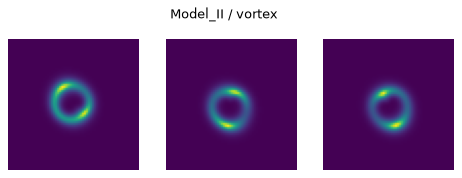

  reply: Great! The simulation has been completed successfully. Here is a summary of the results: |  | - **Model**: Model_II (64x64 pixels, Euclid VIS instrument) | - **Substructure**: Vortex with axion mass \(1 \times 10^{-23}\) eV | - **Number of images**: 3 |  | The images are available, and you can view them using t
  (137s)



In [9]:
if RUN_LIVE_LLM:
    profile = {"subhalos": "vortex", "substructure": "vortex", "axion mass": "1e-23", "how many": "3", "number of": "3", "which model": "Model_II", "model": "Model_II"}
    await_out = await show("make me some lensing images", profile, "vague request")

=== invalid value (500 images, limit is 25): 'Simulate 500 images of a cdm lens with Model_I'


  [agent] Since you requested 500 images but the simulator can only produce up to 25 per request, would you like to reduce the number of images to 25?
  [user] 5
  [agent] I will simulate 5 images of a cdm lens with Model_I. |  | The plan is as follows: | - Model: Model_I (150x150 pixels) | - Substructure: cdm | - Number of images: 5 | - Halo mass: Default (1e12 solar masses) | - Axion mass: Not applicable for cd
  [user] I do not mind, please choose a sensible default.
  [agent] Confirm:   model       : Model_I |   substructure: cdm |   images      : 5 |   halo mass   : 1e+12 solar masses |   redshifts   : lens z=0.5, source z=1.0
  [user] yes
  -> Model_I / cdm / 5 images / shape (150, 150) / axion=None


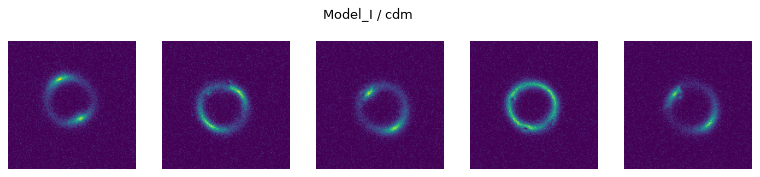

  reply: The simulation of 5 images of a cdm lens with Model_I has been completed successfully. |  | The images are available, and their details are as follows: | - Image size: 150x150 pixels | - Pixel scale: 0.05 arcseconds per pixel | - Instrument: Generic with Gaussian PSF |  | You can review the results using the grid
  (92s)



In [10]:
if RUN_LIVE_LLM:
    profile = {"which model": "Model_I", "model": "Model_I", "substructure": "cdm", "how many": "5", "number of": "5"}
    await_out = await show("Simulate 500 images of a cdm lens with Model_I", profile, "invalid value (500 images, limit is 25)")

In [11]:
if RUN_LIVE_LLM:
    await_out = await show("what is the capital of France?", {}, "off-topic")

=== off-topic: 'what is the capital of France?'


  reply: The request is not related to gravitational lensing simulations. The capital of France is Paris. If you need help with lensing simulations, please provide the necessary details.
  (7s)



## 7. Strategy discussion

**Why this architecture.** The LLM only does what it is good at: reading a loose request, noticing what is missing, and choosing tool arguments. Everything that must be correct is plain code: range and consistency checks (Pydantic), the DeepLenseSim call order, file paths and image statistics. The user sees an exact plan before any compute, and a declined plan is fed back to the model with the user's comment.

**What I observed with `qwen2.5:7b` on CPU (honest list).**
- It handles complete requests, explains that resolution is fixed by the model, and asks for the missing axion mass.
- It is **not deterministic and not fully reliable**. In my live runs it: (a) wrote follow-up questions as plain text instead of calling `ask_user`, (b) once printed its tool call as text (`<tool_call>...`) so nothing ran, (c) once chose a model itself and changed the halo mass although the user never gave either. The code now handles (a) and (b) (a text question goes to the human; a leaked tool call gets one retry), and the instructions forbid (c). The approval gate means the user sees such choices before anything runs.
- Latency is about a minute per LLM call on CPU, which makes a 4-question conversation take several minutes.

**Limits of the simulator wrapper.**
- Only Model_I and Model_II are wired up. Model_III's `set_instrument('hst')` does nothing in the library code, and Model_IV uses a different script structure; I did not wire them.
- Reading `DeepLens.simple_sim_2()`: it ends with `image_real = image_model + image_model`, so no noise term is added for the Euclid configuration. I left the library untouched and mention it only as an observation from the source.
- Resolution cannot be set freely, only through the model choice.

**What I would do next.**
1. Evaluate over a fixed list of prompts (complete, vague, invalid, adversarial) and count outcomes, instead of reading single transcripts, and compare two LLMs (a larger local one or a hosted one).
2. Add Model_III / Model_IV after checking their scripts.
3. For the agentic project itself (SLURM jobs, validating output quality, retraining downstream models), extend the tools: a job-submission tool, an automatic check on the generated images, and a retry policy. The proposal also lists reinforcement learning for planning, which I have not tried.